# Lab 6 - Simple Linear Regression

## Aim

To build a Simple Linear Regression model to study the relationship
between `rainfall_mm_avg` and `pmfby_score`.

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv`.

The feature used is:

- X: `rainfall_mm_avg`

The target variable is:

- y: `pmfby_score`

The relationship was deliberately constructed in the scoring engine
approximately as:

pmfby_score = 55 + 0.02 × (rainfall_mm_avg - 1150) + noise

Therefore, the fitted regression model should recover a slope close to 0.02.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv("../ml/data/labeled_dataset.csv")

X = df[["rainfall_mm_avg"]]
y = df["pmfby_score"]

X.head()

,rainfall_mm_avg
0,1150.0
1,1150.0
2,1150.0
3,1150.0
4,1150.0


## Train-Test Split

The dataset is divided into training and testing sets.

The training data is used to fit the regression model, while the testing
data is used to evaluate its performance.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1232
Testing samples: 308


## Fit Linear Regression Model

In [4]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.019574825864232818
Intercept: 32.70575335198647


## Regression Line Plot

The scatter plot shows the actual data points and the fitted regression line.

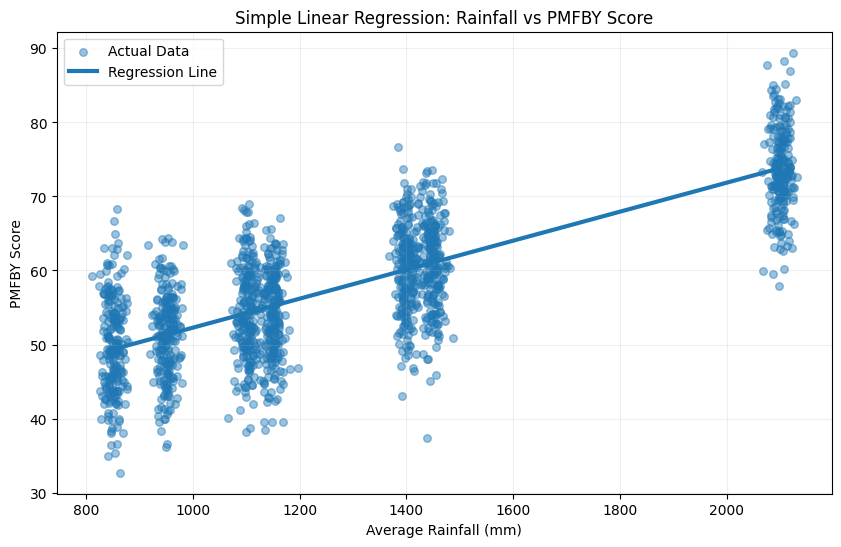

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Small horizontal jitter ONLY for visualization
np.random.seed(42)

x_actual = X["rainfall_mm_avg"].values
y_actual = y.values

x_jittered = x_actual + np.random.normal(
    0, 12, size=len(x_actual)
)

# Smooth regression line
x_line = np.linspace(
    x_actual.min(),
    x_actual.max(),
    200
)

x_line_df = pd.DataFrame({
    "rainfall_mm_avg": x_line
})

y_line = model.predict(x_line_df)

# Plot
plt.figure(figsize=(10, 6))

plt.scatter(
    x_jittered,
    y_actual,
    alpha=0.45,
    s=30,
    label="Actual Data"
)

plt.plot(
    x_line,
    y_line,
    linewidth=3,
    label="Regression Line"
)

plt.xlabel("Average Rainfall (mm)")
plt.ylabel("PMFBY Score")
plt.title("Simple Linear Regression: Rainfall vs PMFBY Score")

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## Model Evaluation

The model is evaluated using:

- R² Score — measures how well the model explains the variation in the target.
- Mean Absolute Error (MAE) — measures the average absolute prediction error.

In [6]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("R² Score:", r2)
print("Mean Absolute Error:", mae)

R² Score: 0.5834217908530732
Mean Absolute Error: 4.862592056945774


## Interpret Slope & Intercept

The slope represents the expected change in `pmfby_score` for every
1-unit increase in `rainfall_mm_avg`.

The scoring engine used an underlying slope of approximately 0.02:

pmfby_score = 55 + 0.02 × (rainfall_mm_avg - 1150) + noise

Therefore, the fitted slope should be reasonably close to 0.02.
The difference is expected because random noise was included in the data.

The intercept represents the predicted PMFBY score when rainfall is zero.

In [7]:
print(f"Fitted slope: {model.coef_[0]:.4f}")
print(f"Expected slope: 0.0200")

print(f"Fitted intercept: {model.intercept_:.4f}")

Fitted slope: 0.0196
Expected slope: 0.0200
Fitted intercept: 32.7058


## Conclusion

A Simple Linear Regression model was developed using `rainfall_mm_avg`
to predict `pmfby_score`.

The model was evaluated using R² and MAE. The fitted slope was compared
with the approximately 0.02 relationship used during dataset construction.

A slope close to 0.02 indicates that the regression model successfully
recovered the underlying relationship between rainfall and the PMFBY score.